# Chapitre 10 - Cours 3 : MapReduce, le shuffle et les jointures

MapReduce a rendu le traitement par lots distribué accessible : on écrit deux fonctions,
le framework se charge du reste (découpage, placement, tri distribué, relances).
C'est le modèle central de ce chapitre du livre, implémenté par Hadoop et repris par de nombreux systèmes.
Ce cours construit un MapReduce miniature (`B.run_mapreduce`) qui écrit de vrais
fichiers de shuffle, puis s'en sert pour les jointures et les regroupements. Il couvre
les sections *MapReduce Job Execution* (*Distributed execution of MapReduce*, *MapReduce workflows*), *Reduce-Side Joins and Grouping* (avec *Handling skew*) et *Map-Side Joins*.

**Plan.**

1. Le modèle MapReduce : un mappeur, un réducteur, et un tri entre les deux.
2. L'exécution distribuée : le shuffle, un tri distribué.
3. Enchaîner des jobs MapReduce.
4. Jointures et regroupements côté reduce (jointure tri-fusion).
5. L'asymétrie : clés chaudes et réducteurs à la traîne.
6. Jointures côté map : hachage diffusé, hachage partitionné, fusion.

In [1]:
import json
import os
import subprocess
import sys
import tempfile
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
lines = B.generate_access_log(200_000, n_urls=2000, s=1.1, seed=2)

## 1. Le modèle MapReduce (section *MapReduce Job Execution*)

Un job MapReduce reprend exactement les étapes du pipeline Unix du cours 1 :

1. **lire** les fichiers d'entrée et les découper en enregistrements (une ligne de
   journal) ;
2. appeler le **mappeur** sur chaque enregistrement pour en extraire une clé et une
   valeur (`awk '{print $7}'` : la clé est l'URL, la valeur est vide) ;
3. **trier** tous les couples (clé, valeur) par clé (le premier `sort`) ;
4. appeler le **réducteur** sur les valeurs de chaque clé, désormais adjacentes
   (`uniq -c` compte les lignes égales consécutives).

Le programmeur n'écrit que les étapes 2 et 4. Le mappeur est appelé une fois par
enregistrement, sans garder d'état d'un appel à l'autre, et peut émettre zéro, un ou
plusieurs couples. Le réducteur reçoit une clé et un itérateur sur toutes ses valeurs.
Le tri de l'étape 3 est **implicite** : le framework le fait toujours.

In [2]:
def mappeur_url(ligne):
    yield B.url_of(ligne), 1          # clé = URL, valeur = 1


def reducteur_somme(url, valeurs):
    yield [url, sum(valeurs)]


sorties, compteurs = B.run_mapreduce([lines], mappeur_url, reducteur_somme, n_reducers=1)
top = sorted(sorties[0], key=lambda r: -r[1])[:5]
pd.DataFrame(top, columns=["URL", "requêtes"])

,URL,requêtes
0,/,33988
1,/favicon.ico,15685
2,/2016/06/15/local-crdt.html,10253
3,/2012/01/04/clocks-automerge-consensus.html,7350
4,/2012/08/13/shuffle-byzantine-isolation.html,5692


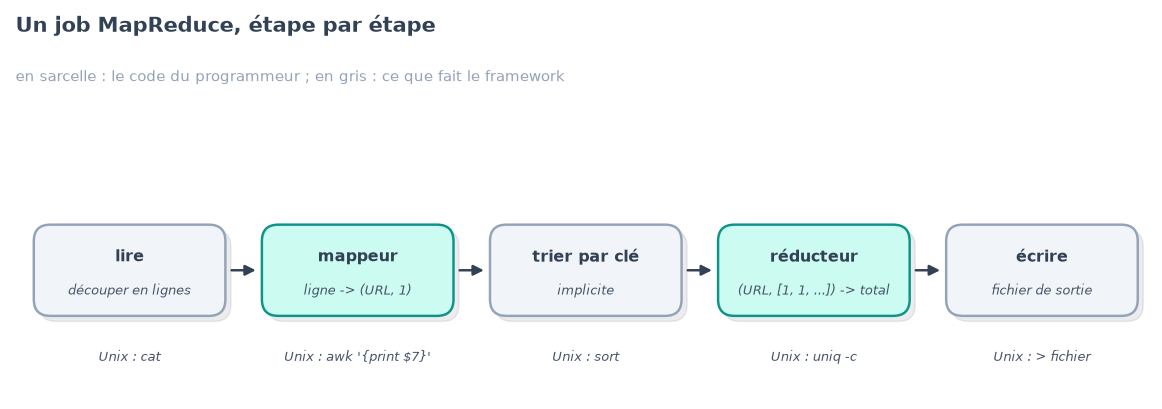

In [3]:
d = Diagram(12.5, 3.3, title="Un job MapReduce, étape par étape",
            subtitle="en sarcelle : le code du programmeur ; en gris : ce que fait le framework")
d.flow([("lire", "lire", "découper en lignes"), ("map", "mappeur", "ligne -> (URL, 1)"),
        ("tri", "trier par clé", "implicite"), ("red", "réducteur", "(URL, [1, 1, ...]) -> total"),
        ("ecr", "écrire", "fichier de sortie")], y=1.4, x0=1.3, dx=2.5, w=2.1, h=1.0,
       colors=[GRAY, TEAL, GRAY, TEAL, GRAY])
for x, t in [(1.3, "cat"), (3.8, "awk '{print $7}'"), (6.3, "sort"), (8.8, "uniq -c"), (11.3, "> fichier")]:
    d.note(x, 0.45, f"Unix : {t}", fontsize=8.5)
d.show()

**Pourquoi c'est parallélisable : la programmation fonctionnelle.** Les noms viennent des
fonctions d'ordre supérieur `map` et `reduce` (ou *fold*) de Lisp. Comme chaque appel au
mappeur ou au réducteur ne dépend que de ce que le framework lui passe (pas d'état
partagé, pas d'effet de bord), le framework est libre de lancer les appels en parallèle
sur des machines différentes, et de **rejouer** un appel ailleurs si une tâche échoue.
Le top 5 trié par nombre décroissant exige un second tri : en MapReduce, c'est un second
job (section 3).

> **À retenir.** MapReduce = mappeur (extraire une clé) + tri implicite par clé +
> réducteur (traiter chaque groupe). Des fonctions sans état ni effet de bord permettent
> au framework de paralléliser et de rejouer les tâches librement.